# 第六部分 泰坦尼克号乘客数据分析
## 项目概述
- 数据来源：数据来源于机器学习竞赛网站Kaggle
- 事件：泰坦尼克号游轮沉没事件
- 分析目的：探索乘客数据的每个特征的分布以及与是否获救之间的关系

## 数据初探
- 数据集的整体状况
- 是否有缺失值、异常值
- 数据的取值范围
- 每个特征的含义

In [7]:
# 准备工作
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
%config InlineBackend.figure_format="svg"
## 设置中文显示
plt.rcParams["font.sans-serif"] = "SimHei"
plt.rcParams["axes.unicode_minus"] = False

In [16]:
# 读入数据
df = pd.read_csv("data/titanic_data.csv")
df.head()

,pclass,survived,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked
0,1.0,1.0,"Allen, Miss. Elisabeth Walton",female,29.0000,0.0,0.0,24160,211.3375,B5,S
1,1.0,1.0,"Allison, Master. Hudson Trevor",male,0.9167,1.0,2.0,113781,151.5500,C22 C26,S
2,1.0,0.0,"Allison, Miss. Helen Loraine",female,2.0000,1.0,2.0,113781,151.5500,C22 C26,S
3,1.0,0.0,"Allison, Mr. Hudson Joshua Creighton",male,30.0000,1.0,2.0,113781,151.5500,C22 C26,S
4,1.0,0.0,"Allison, Mrs. Hudson J C (Bessie Waldo Daniels)",female,25.0000,1.0,2.0,113781,151.5500,C22 C26,S


### 特征含义
- pclass：船舱等级（1、2、3等舱）
- survived：是否获救（1-获救，0-遇难）
- name：乘客姓名（包含姓名中的Title）
- sex：乘客性别
- sibsp：（堂）兄弟姐妹人数
- parch：直系亲属人数
- ticket：船票编号
- fare：票价
- cabin：船舱编号
- embarked：登船港口（S-南安普顿，C-瑟堡，Q-皇后镇）

In [9]:
df.tail()
# 删除空行
df.drop(1309, axis=0, inplace=True)

In [17]:
# 数据基本信息
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1310 entries, 0 to 1309
Data columns (total 11 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   pclass    1309 non-null   float64
 1   survived  1309 non-null   float64
 2   name      1309 non-null   str    
 3   sex       1309 non-null   str    
 4   age       1046 non-null   float64
 5   sibsp     1309 non-null   float64
 6   parch     1309 non-null   float64
 7   ticket    1309 non-null   str    
 8   fare      1308 non-null   float64
 9   cabin     295 non-null    str    
 10  embarked  1307 non-null   str    
dtypes: float64(6), str(5)
memory usage: 112.7 KB


### 数据信息
- 乘客总数：1309
- 特征总数：11
- 缺失值：年龄、票价、船舱编号、登船港口

In [13]:
# 数值数据
df.describe()

,pclass,survived,age,sibsp,parch,fare
count,1309.000000,1309.000000,1046.000000,1309.000000,1309.000000,1308.000000
mean,2.294882,0.381971,29.881135,0.498854,0.385027,33.295479
std,0.837836,0.486055,14.413500,1.041658,0.865560,51.758668
min,1.000000,0.000000,0.166700,0.000000,0.000000,0.000000
25%,2.000000,0.000000,21.000000,0.000000,0.000000,7.895800
50%,3.000000,0.000000,28.000000,0.000000,0.000000,14.454200
75%,3.000000,1.000000,39.000000,1.000000,0.000000,31.275000
max,3.000000,1.000000,80.000000,8.000000,9.000000,512.329200


### 数值特征统计信息
- 平均年龄29.9岁，最大80岁，最小两个月左右
- 获救比例38.2%
- 一二等舱乘客较少，超过半数以上的是三等舱
- 大多数乘客独自一人，没有亲属同行

## 数据预处理
- 包括缺失值处理和数据转换

### 缺失值处理
- 票价：只有一个缺失值，采用前向填充

In [15]:
# 票价缺失值：前向填充
df["fare"].fillna(method="ffill", inplace=True)

TypeError: NDFrame.fillna() got an unexpected keyword argument 'method'

- 年龄：采用均值填充

In [18]:
# 年龄缺失值：均值填充
aver_age = np.round(df["age"].mean(), 1)
df["age"].fillna(aver_age, inplace=True)

C:\Users\31718\AppData\Local\Temp\ipykernel_32092\3090485670.py:3: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  df["age"].fillna(aver_age, inplace=True)


0       29.0000
1        0.9167
2        2.0000
3       30.0000
4       25.0000
         ...   
1305    29.9000
1306    26.5000
1307    27.0000
1308    29.0000
1309    29.9000
Name: age, Length: 1310, dtype: float64

- 登船港口：有两个缺失值，采用最多值填充

In [19]:
# 登船港口缺失值采用最多的值填充
df["embarked"].value_counts()
df["embarked"].fillna("S", inplace=True)

C:\Users\31718\AppData\Local\Temp\ipykernel_32092\500751976.py:3: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  df["embarked"].fillna("S", inplace=True)


0       S
1       S
2       S
3       S
4       S
       ..
1305    C
1306    C
1307    C
1308    S
1309    S
Name: embarked, Length: 1310, dtype: str

- 船舱编号：缺失值太多，可以删除列
- 这里采用增加一列的方法，标注有无船舱编号

In [9]:
# 船舱编号缺失值：转换为有无编号
df["have_cabin"] = df["cabin"].notnull()
df["have_cabin"].value_counts()

False    1014
True      295
Name: have_cabin, dtype: int64

In [10]:
# 删除船舱编号列
df.drop("cabin", axis=1, inplace=True)

In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 1309 entries, 0 to 1308
Data columns (total 11 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   pclass      1309 non-null   float64
 1   survived    1309 non-null   float64
 2   name        1309 non-null   object 
 3   sex         1309 non-null   object 
 4   age         1309 non-null   float64
 5   sibsp       1309 non-null   float64
 6   parch       1309 non-null   float64
 7   ticket      1309 non-null   object 
 8   fare        1309 non-null   float64
 9   embarked    1309 non-null   object 
 10  have_cabin  1309 non-null   bool   
dtypes: bool(1), float64(6), object(4)
memory usage: 113.8+ KB


### 数据转换
- 主要是对亲属的两个字段以及姓名字段做一些处理
- 后续在分析过程中对年龄和票价做一些分段转换处理

- 亲属字段(sibsp和parch)：增加一个familly字段作为亲属人数

In [12]:
# 亲属字段
df["familly"] = df["sibsp"] + df["parch"]
df["familly"].value_counts()

0.0     790
1.0     235
2.0     159
3.0      43
5.0      25
4.0      22
6.0      16
10.0     11
7.0       8
Name: familly, dtype: int64

In [13]:
# 好奇一下，最大家族有多少人获救
df.loc[df["familly"]==10, "survived"].value_counts()

0.0    11
Name: survived, dtype: int64

- 定义一个single字段，标注乘客是否独自一人

In [14]:
# 独自一人的乘客：single
df["single"] = df["familly"]==0.0
df["single"].value_counts()

True     790
False    519
Name: single, dtype: int64

- 姓名字段：提取name中的Title

In [15]:
# 姓名字段：提取Title（头衔）
df["title"] = df["name"].str.split(",").str[1].str.split(".").str[0].str.strip()
df["title"].value_counts()

Mr              757
Miss            260
Mrs             197
Master           61
Rev               8
Dr                8
Col               4
Mlle              2
Ms                2
Major             2
Sir               1
Capt              1
the Countess      1
Jonkheer          1
Lady              1
Mme               1
Don               1
Dona              1
Name: title, dtype: int64

- 用字典将Title分类并重新映射赋值

In [16]:
title_mapDict = {
                    "Capt":       "Officer",
                    "Col":        "Officer",
                    "Major":      "Officer",
                    "Jonkheer":   "Royalty",
                    "Don":        "Royalty",
                    "Sir" :       "Royalty",
                    "Dr":         "Officer",
                    "Rev":        "Officer",
                    "the Countess":"Royalty",
                    "Dona":       "Royalty",
                    "Mme":        "Mrs",
                    "Mlle":       "Miss",
                    "Ms":         "Mrs",
                    "Mr" :        "Mr",
                    "Mrs" :       "Mrs",
                    "Miss" :      "Miss",
                    "Master" :    "Mr",
                    "Lady" :      "Royalty"
                }

In [17]:
df["title"] = df["title"].map(title_mapDict)
df["title"].value_counts()

Mr         818
Miss       262
Mrs        200
Officer     23
Royalty      6
Name: title, dtype: int64

In [18]:
df.drop(["name","sibsp","parch","ticket"], axis=1, inplace=True)
df.head()

,pclass,survived,sex,age,fare,embarked,have_cabin,familly,single,title
0,1.0,1.0,female,29.0000,211.3375,S,True,0.0,True,Miss
1,1.0,1.0,male,0.9167,151.5500,S,True,3.0,False,Mr
2,1.0,0.0,female,2.0000,151.5500,S,True,3.0,False,Miss
3,1.0,0.0,male,30.0000,151.5500,S,True,3.0,False,Mr
4,1.0,0.0,female,25.0000,151.5500,S,True,3.0,False,Mrs


In [19]:
# 保存数据
df.to_csv("data/titan_clean.csv", index=False)

## 数据分析
乘客有多个特征，哪些特征更有用？如何利用这些特征进行数据分析

### 乘客单个特征分布的分析
分析乘客每个特征的取值的分布

In [6]:
# 准备工作
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
%config InlineBackend.figure_format="svg"
## 设置中文显示
plt.rcParams["font.sans-serif"] = "SimHei"
plt.rcParams["axes.unicode_minus"] = False
# 读取数据
df = pd.read_csv("data/titan_clean.csv")
df.head()

FileNotFoundError: [Errno 2] No such file or directory: 'data/titan_clean.csv'

NameError: name 'df' is not defined

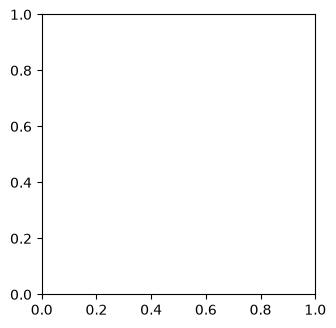

In [3]:
# 图形大小
fig = plt.figure(figsize=(12,8))
fig.set(alpha = 0.2)
# 设置子图，获救分布
plt.subplot2grid((2,3),(0,0))
df["survived"].value_counts().plot.pie(title="获救分布(1为获救)", autopct="%.1f%%", explode=[0.01,0.01])
# 舱位等级分布
plt.subplot2grid((2,3),(0,1))
df["pclass"].value_counts().plot.bar(title="舱位等级分布", xlabel="舱位等级", ylabel="人数")
plt.xticks([0,1,2],["三等舱","一等舱","二等舱"], rotation=0)
# 性别分布
plt.subplot2grid((2,3),(0,2))
df["sex"].value_counts().plot.pie(title="性别分布", autopct="%.1f%%", explode=[0.01,0.01])
# 年龄分布
plt.subplot2grid((2,3),(1,0))
df["age"].plot.hist(title="年龄分布", bins=[0,3,14,40,60,80,100], rwidth=0.95, edgecolor="red")
# 登船港口分布
plt.subplot2grid((2,3),(1,1))
df["embarked"].value_counts().plot.bar(title="登船港口人数分布")
# 票价分布
plt.subplot2grid((2,3),(1,2))
sns.boxplot(data=df, y="fare")
# 显示图形
plt.subplots_adjust(hspace=0.4)
plt.show();

#### 单个特征分布分析的结论
- 获救比例38.2%，大多数乘客遇难
- 超过一半的乘客在三等舱
- 男性乘客几乎是女性的2倍
- 乘客大多数是青壮年，儿童和老人占比很少
- 大多数乘客是从南安普顿港口登船
- 乘客票价绝大多数在50元以下

### 乘客多个特征结合分析

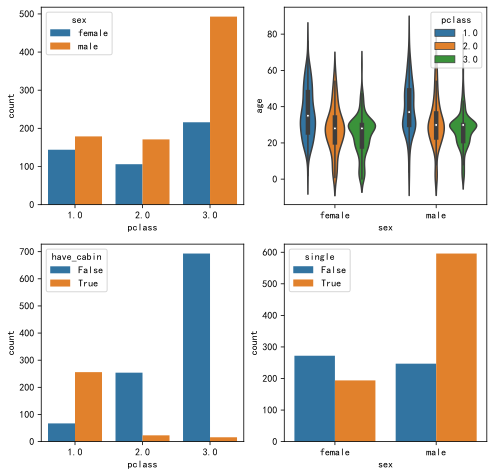

In [22]:
# # 图形大小
fig = plt.figure(figsize=(8,8))
fig.set(alpha = 0.2)
# 设置子图，舱位和性别分布
plt.subplot2grid((2,2),(0,0))
# df.groupby(by=["pclass","sex"]).size().plot.bar()
sns.countplot(data=df, x="pclass", hue="sex")
# 年龄、性别以及舱位
plt.subplot2grid((2,2),(0,1))
sns.violinplot(data=df, x="sex",y="age",  hue="pclass")
# 舱位和有无船舱编号
plt.subplot2grid((2,2),(1,0))
sns.countplot(data=df, x="pclass", hue="have_cabin")
# 是否独自一人和性别
plt.subplot2grid((2,2),(1,1))
sns.countplot(data=df, x="sex", hue="single")
# 显示图形
plt.show();

#### 乘客多特征结合分析的一些结论
- 三等舱以男性为主
- 三等舱以青壮年居多，一等舱以中年居多
- 有舱位编号的乘客绝大多数是一等舱
- 独自一人的乘客以男性为主

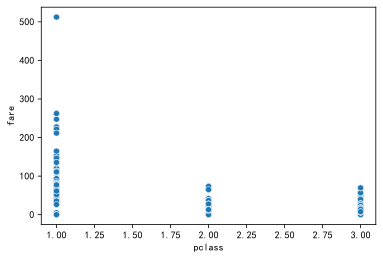

In [23]:
# 舱位和票价的散点图
sns.scatterplot(data=df, x="pclass", y="fare")
plt.show();

### 乘客其他特征和获救之间的关系
一些想法
- 年龄和性别（妇孺优先）
- 舱位等级（财富和地位）
- 登船港口、有无编号、是否独自一人、票价（多因素对获救的影响）

#### 船舱等级

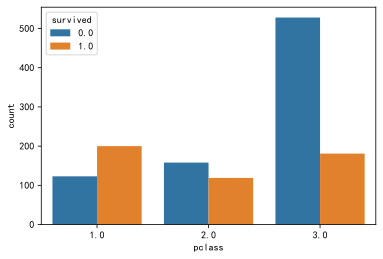

In [24]:
# 船舱等级和获救之间的关系
sns.countplot(data=df, x="pclass", hue="survived");

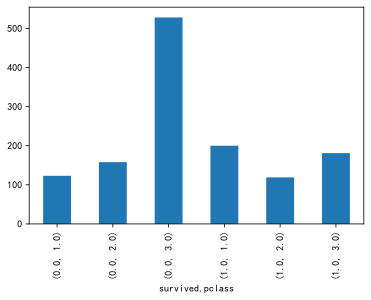

In [26]:
# pandas绘图
df.groupby(by=["survived","pclass"]).size().plot.bar();

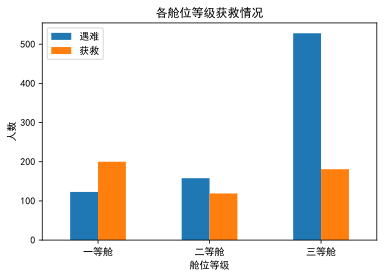

In [34]:
# 手工计算的方式
s_0 = df.loc[df["survived"]==0.0, "pclass"].value_counts()
s_1 = df.loc[df["survived"]==1.0, "pclass"].value_counts()
df_pclass = pd.DataFrame({"遇难":s_0, "获救":s_1})
df_pclass.plot.bar(title="各舱位等级获救情况")
plt.xlabel("舱位等级")
plt.ylabel("人数")
plt.xticks([0,1,2],["一等舱","二等舱","三等舱"], rotation=0)
plt.show();

- 结论：一等舱获救比例最高，三等舱获救比例相当低，财富和地位真能买到生命？

#### 性别

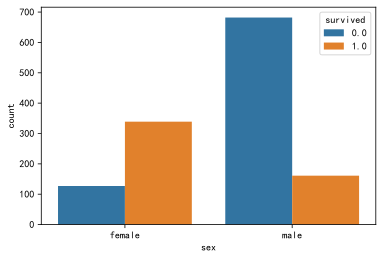

In [35]:
# 性别和获救的关系
sns.countplot(data=df, x="sex", hue="survived");

- 结论：女性绝大多数获救，男性绝大多数遇难。女士优先的绅士文化根深蒂固。

#### 性别和舱位等级

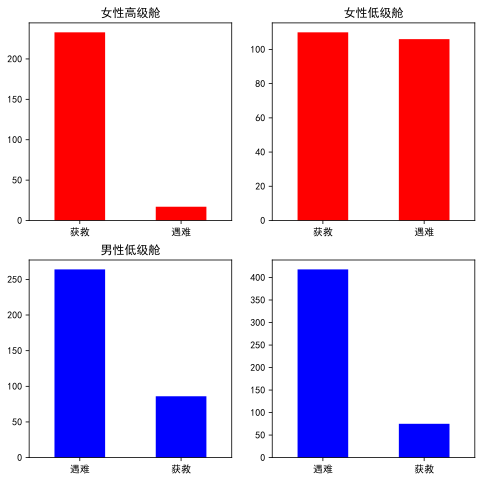

In [40]:
# 性别和舱位等级对获救的影响
fig = plt.figure(figsize=(8,8))
# 子图
ax1 = fig.add_subplot(221)
ax2 = fig.add_subplot(222)
ax3 = fig.add_subplot(223)
ax4 = fig.add_subplot(224)
# 女性高级舱
df.survived[df.sex=="female"][df.pclass!=3].value_counts().plot.bar(color="red", ax=ax1)
ax1.set_title("女性高级舱")
ax1.set_xticklabels(["获救","遇难"], rotation=0)
# 女性低级舱
df.survived[df.sex=="female"][df.pclass==3].value_counts().plot.bar(color="red", ax=ax2)
ax2.set_title("女性低级舱")
ax2.set_xticklabels(["获救","遇难"], rotation=0)
# 男性高级舱
df.survived[df.sex=="male"][df.pclass!=3].value_counts().plot.bar(color="blue", ax=ax3)
ax3.set_title("男性高级舱")
ax3.set_xticklabels(["遇难","获救"], rotation=0)
# 男性低级舱
df.survived[df.sex=="male"][df.pclass==3].value_counts().plot.bar(color="blue", ax=ax4)
ax3.set_title("男性低级舱")
ax4.set_xticklabels(["遇难","获救"], rotation=0)
# 显示图形
plt.show();

- 结论：女性高级舱几乎全部获救；男性高级舱没有女性的待遇，但仍然比低级舱获救比例高；最悲惨的是男性低级舱，几乎全部遇难。

#### 登船港口

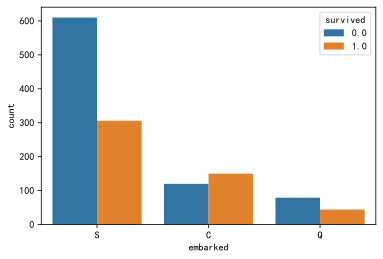

In [41]:
# 港口和获救的关系
sns.countplot(data=df, x="embarked", hue="survived");

- 结论：瑟堡港登船的乘客获救比例明显高一些（法国人浪漫不刻板，逃生能力强？）

In [42]:
# 出于好奇，探究一下瑟堡港乘客的性别和舱位
df[df["embarked"]=="C"].groupby(by=["sex","pclass"]).size()

sex     pclass
female  1.0       71
        2.0       11
        3.0       31
male    1.0       70
        2.0       17
        3.0       70
dtype: int64

#### 舱位编号

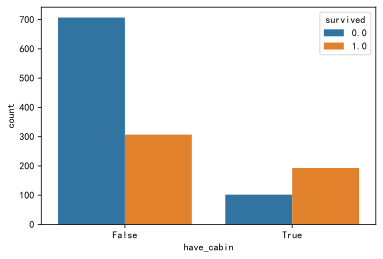

In [43]:
sns.countplot(data=df, x="have_cabin", hue="survived");

- 结论：有舱位编号获救比例高得多。结合前面的分析，有编号的大多在一等舱

In [44]:
df[df.have_cabin==True].groupby("pclass").size()

pclass
1.0    256
2.0     23
3.0     16
dtype: int64

#### 独自一人

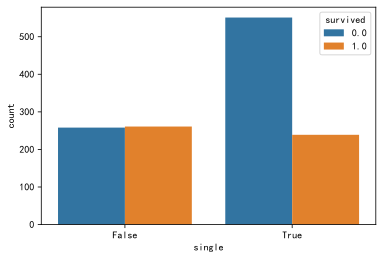

In [45]:
sns.countplot(data=df, x="single", hue="survived");

- 结论：独自一人遇难的比例高得多（人多力量大？大多数是男性）

In [47]:
df[df.single==True].groupby(by="sex").size()

sex
female    194
male      596
dtype: int64

#### 头衔（Title）

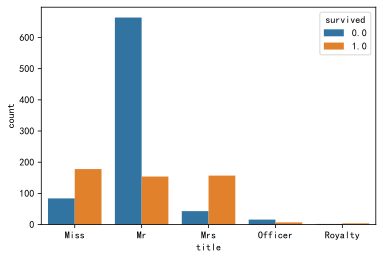

In [48]:
sns.countplot(data=df, x="title", hue="survived");

- 结论：Miss和Mrs获救比例高（女性）， Mr获救比例最低（男性）

#### 其他分析

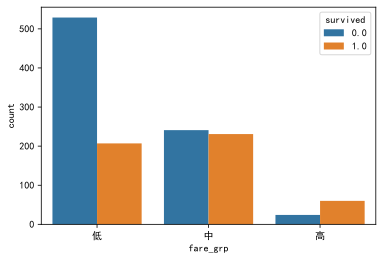

In [49]:
# 票价
df["fare_grp"] = pd.cut(df.fare, bins=[0,20,100,1000], labels=["低","中","高"])
sns.countplot(data=df, x="fare_grp", hue="survived");

In [50]:
df[df.fare>100].groupby(by="pclass").size()

pclass
1.0    84
dtype: int64

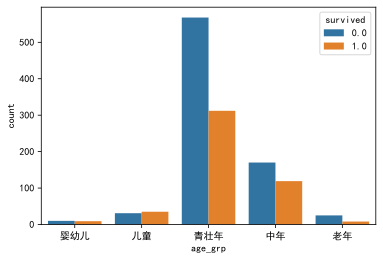

In [51]:
# 年龄
df["age_grp"] = pd.cut(df.age, bins=[1,3,14,35,60,100], labels=["婴幼儿","儿童","青壮年","中年","老年"])
sns.countplot(data=df, x="age_grp", hue="survived");

- 结论：高票价获救比例高（大多一等舱），青壮年遇难比例高（大多三等舱）

## 总结
- 女性获救比例高
- 高级舱获救比例高
- 儿童获救比例比较高
- 有仓位编号获救比例高
- 独自一人遇难比例高
- 瑟堡港登船或九比例高

## 后续工作
为机器学习做准备
- 连续变量离散化
- 分类数据哑变量处理
- 划分训练集和测试集
- 机器学习算法
- 算法评估和部署